# 03 · Comparación de modelos y modelo exportado

Random Forest vs XGBoost vs red neuronal (MLP) con los mismos pliegues espaciales. La elección se hace con la CV de desarrollo; el test se mira una vez.

In [1]:
import os, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)

# Raíz del paquete: la carpeta que contiene config/motor.json
RAIZ = Path.cwd()
while not (RAIZ / "config" / "motor.json").is_file() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
SAL = Path(os.environ.get("CLASIFICADOR_SALIDAS", RAIZ / "salidas"))
ENT = RAIZ / "datos_entrada" / "processed"
TY = RAIZ / "resultados_TY" / "run_004"
if not (TY / "02_particion" / "particion.parquet").is_file():
    TY = RAIZ / "resultados_TY" / "run_003"   # respaldo: corrida anterior incluida en el paquete
print("raíz:", RAIZ, "| salidas:", SAL, "| TY:", TY.name)

raíz: /home/claude/build/Modelo | salidas: /home/claude/build/Modelo/salidas | TY: run_004


In [2]:
M = SAL / "5_modelos"
comp = pd.read_csv(M / "comparacion_global.csv")
cols = [c for c in ["experimento", "modelo", "elegido_por_cv", "potencia_peso", "cv_macro_f1", "cv_balanced_accuracy",
                    "cv_ap_positivas", "cv_recall_positivas", "test_macro_f1", "test_recall_positivas", "test_precision_positivas"] if c in comp]
comp[cols]

,experimento,modelo,elegido_por_cv,potencia_peso,cv_macro_f1,cv_balanced_accuracy,cv_ap_positivas,cv_recall_positivas,test_macro_f1,test_recall_positivas,test_precision_positivas
0,A_catalogo_5clases,rf,False,0.25,0.7531,0.7241,0.9257,0.8297,0.7532,0.8394,0.9419
1,A_catalogo_5clases,xgb,True,0.25,0.7808,0.7528,0.9257,0.8374,0.7814,0.8394,0.9205
2,A_catalogo_5clases,mlp,False,0.25,0.7469,0.7291,0.9149,0.8335,0.7539,0.8446,0.9261
3,B_catalogo_binario,rf,True,0.25,0.9384,0.9129,0.9277,0.8297,0.9359,0.8290,0.9412
4,B_catalogo_binario,xgb,False,0.25,0.9377,0.9151,0.9254,0.8348,0.9326,0.8394,0.9153
5,B_catalogo_binario,mlp,False,0.25,0.9378,0.9157,0.9311,0.8361,0.9316,0.8446,0.9056
6,C_catalogo_5clases_subconjunto,rf,True,0.25,0.7500,0.7325,0.9845,0.9656,0.7729,0.9661,0.9500
7,C_catalogo_5clases_subconjunto,xgb,False,0.25,0.7358,0.7203,0.9850,0.9347,0.7922,0.9661,0.9344
8,C_catalogo_5clases_subconjunto,mlp,False,0.25,0.7181,0.7156,0.9757,0.8660,0.7259,0.8475,0.9615
9,D_catalogo_spherex_5clases,rf,True,0.25,0.7563,0.7433,0.9879,0.9485,0.8325,0.9661,0.9344


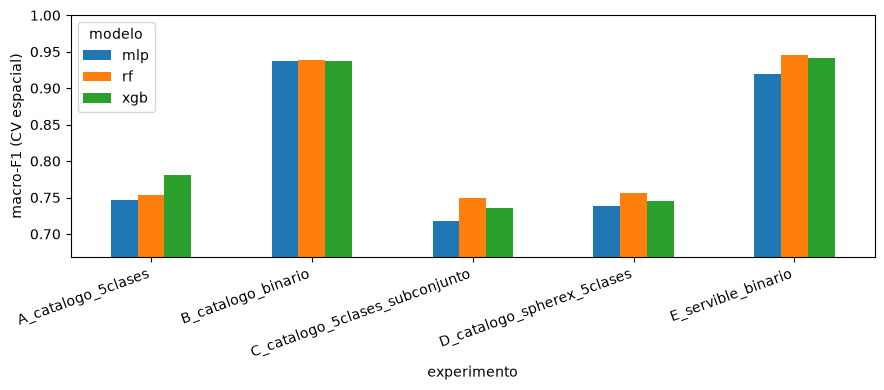

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
piv = comp.pivot(index="experimento", columns="modelo", values="cv_macro_f1")
piv.plot.bar(ax=ax); ax.set_ylabel("macro-F1 (CV espacial)"); ax.set_ylim(max(0, piv.min().min() - .05), 1)
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

## Matrices de confusión del modelo elegido en cada experimento

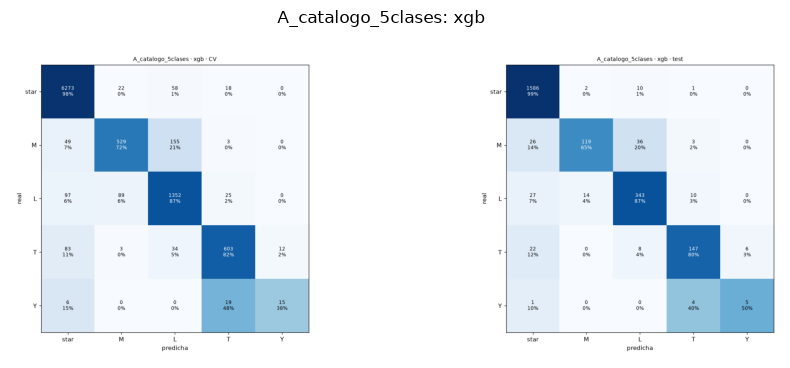

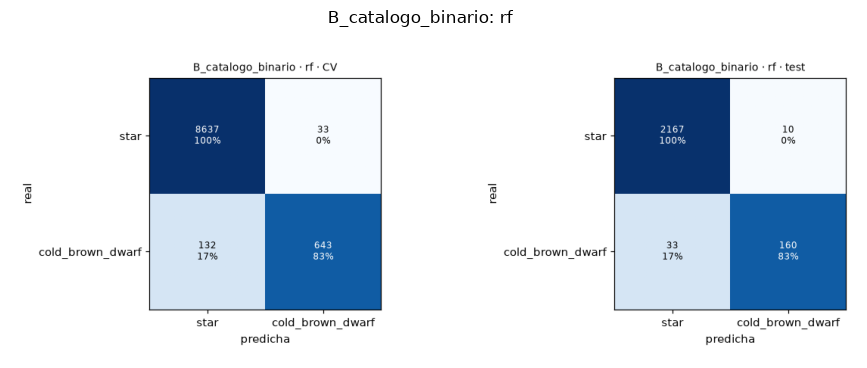

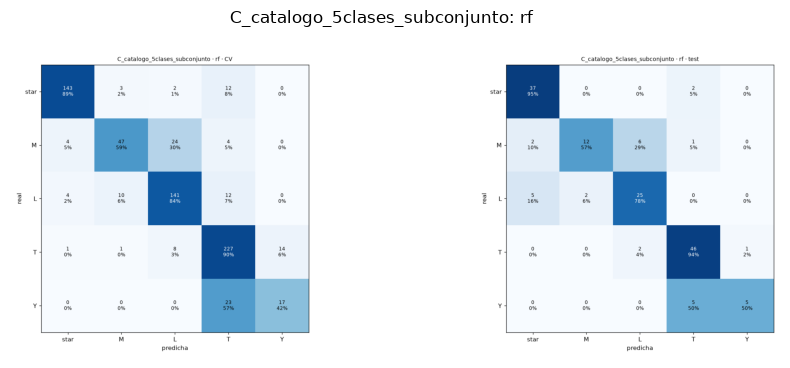

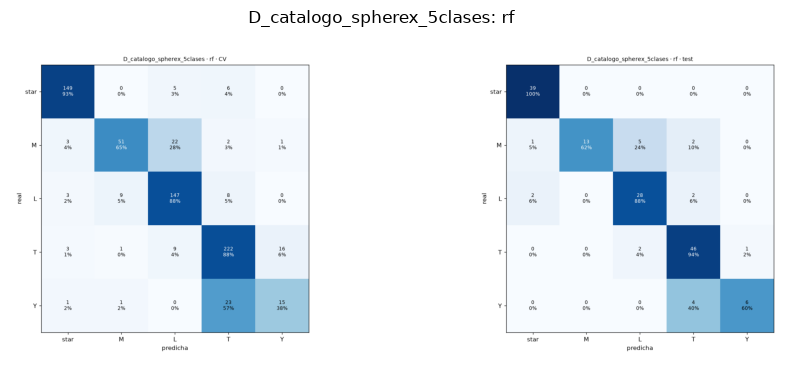

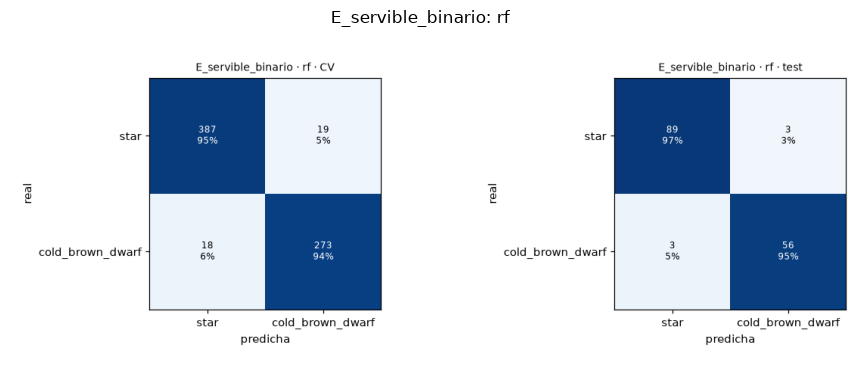

In [4]:
from matplotlib.image import imread
for e in sorted(p for p in M.iterdir() if p.is_dir()):
    met = json.loads((e / "metricas.json").read_text(encoding="utf-8"))
    tipo = met["elegido"]
    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    for ax, kind in zip(axs, ("cv", "test")):
        ax.imshow(imread(e / f"confusion_{kind}_{tipo}.png")); ax.axis("off")
    fig.suptitle(f"{e.name}: {tipo}"); plt.show()

## Importancia por permutación (caída de macro-F1 al desordenar)

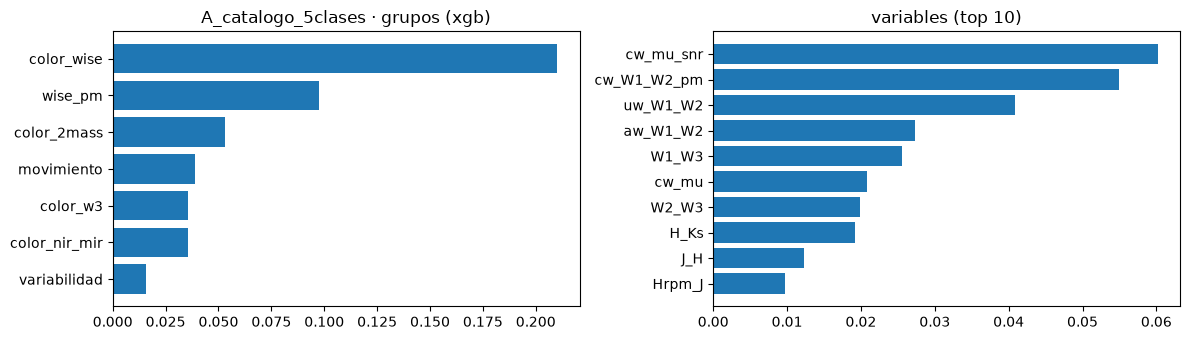

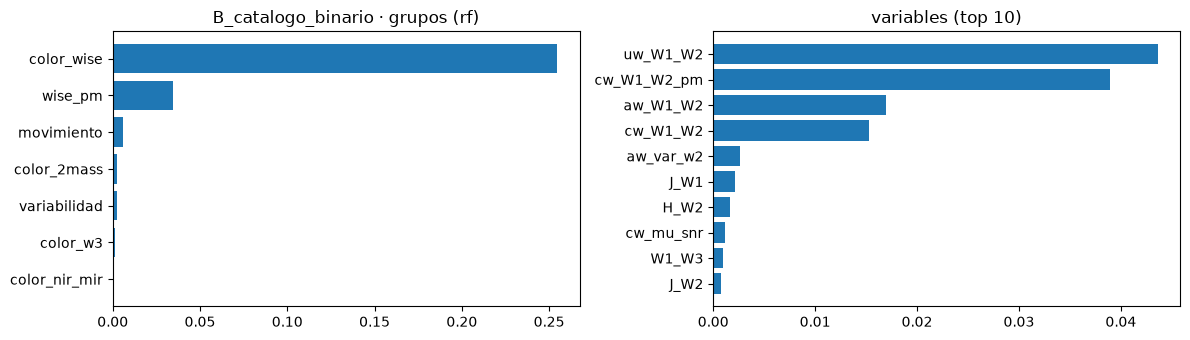

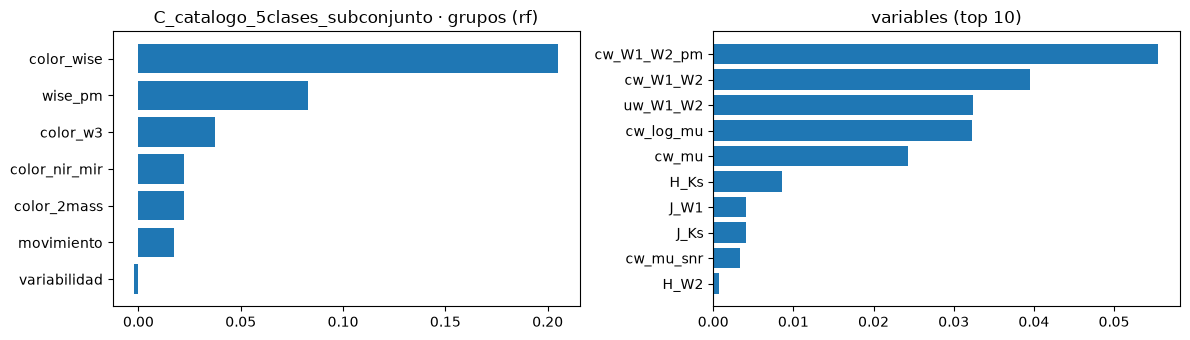

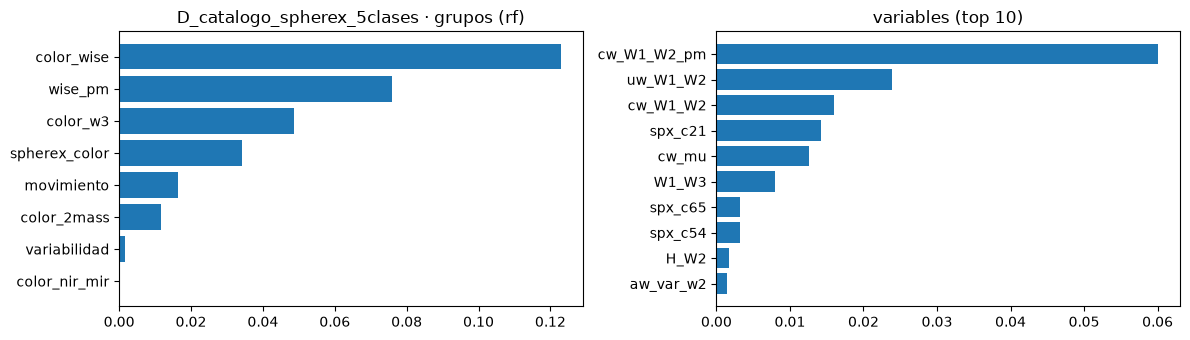

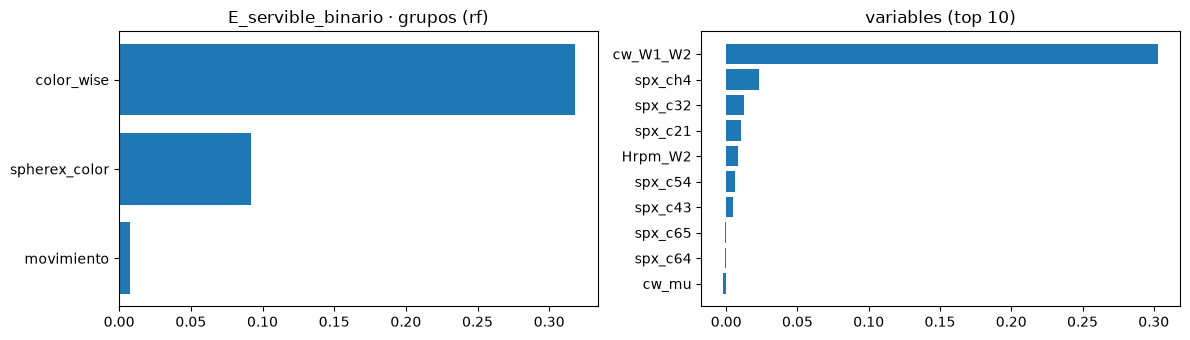

In [5]:
for e in sorted(p for p in M.iterdir() if p.is_dir()):
    met = json.loads((e / "metricas.json").read_text(encoding="utf-8"))
    tipo = met["elegido"]
    g = pd.read_csv(e / f"importancia_grupos_{tipo}.csv")
    v = pd.read_csv(e / f"importancia_variables_{tipo}.csv").head(10)
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
    axs[0].barh(g["grupo"], g["caida_macro_f1"]); axs[0].invert_yaxis(); axs[0].set_title(f"{e.name} · grupos ({tipo})")
    axs[1].barh(v["variable"], v["caida_macro_f1"]); axs[1].invert_yaxis(); axs[1].set_title("variables (top 10)")
    plt.tight_layout(); plt.show()

## Modelo exportado para el backend

In [6]:
X = SAL / "6_exportar"
if (X / "metadata.json").is_file():
    meta = json.loads((X / "metadata.json").read_text(encoding="utf-8"))
    ver = json.loads((X / "verificacion.json").read_text(encoding="utf-8"))
    print(json.dumps({k: meta[k] for k in ("model_version", "features", "classes", "thresholds", "fill_values")}, indent=1))
    print("verificación ONNX:", {k: ver[k] for k in ("ok", "max_dif_probabilidades", "acuerdo_clase", "n_test")})
else:
    print("Aún no se exportó (etapa 6).")

{
 "model_version": "motor-rf-E_servible_binario-spherex-2026-11-16T0256",
 "features": [
  "cw_W1_W2",
  "cw_mu",
  "Hrpm_W2",
  "spx_c21",
  "spx_c32",
  "spx_c43",
  "spx_c54",
  "spx_c65",
  "spx_c64",
  "spx_ch4"
 ],
 "classes": [
  "star",
  "cold_brown_dwarf"
 ],
 "thresholds": {
  "cold_brown_dwarf": 0.5
 },
 "fill_values": {
  "cw_W1_W2": 0.34800000000000075,
  "cw_mu": 0.15012990738314913,
  "Hrpm_W2": 15.070248340936764,
  "spx_c21": -0.651065558758797,
  "spx_c32": -0.012353231554913083,
  "spx_c43": 0.39644475134971874,
  "spx_c54": -0.05543021596838665,
  "spx_c65": 0.44363594229807973,
  "spx_c64": 0.4701077946236018,
  "spx_ch4": 0.06741458781692235
 }
}
verificación ONNX: {'ok': True, 'max_dif_probabilidades': 3.3872626226116864e-07, 'acuerdo_clase': 1.0, 'n_test': 151}
